# COMP 5326, Fall 2026
## Wasif Hussain - P23404481
**Homework 3**

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay,
                             confusion_matrix, r2_score, mean_squared_error)

RANDOM_SEED = 42
np.set_printoptions(precision=6, suppress=True)

def input_path(filename):
    for folder in [Path.cwd(), Path.cwd() / 'data', Path('/content'), Path('/content/data'), Path('/mnt/data')]:
        path = folder / filename
        if path.is_file():
            return path
    from urllib.request import urlretrieve
    target = (Path('/content') if Path('/content').is_dir() else Path.cwd()) / filename
    url = ('https://raw.githubusercontent.com/WasifHussain/Classical-ML-Algorithms/'
           'main/data/' + filename)
    try:
        urlretrieve(url, target)
    except Exception as exc:
        if target.exists():
            target.unlink()
        raise FileNotFoundError(f'{filename} could not be found or downloaded from GitHub.') from exc
    return target
print('Imports successful; random_state =', RANDOM_SEED)

Imports successful; random_state = 42


## Problem 1(a): Surf prediction with nearest neighbors
For Manhattan distance, compute $d_1(q,x)=\sum_j |q_j-x_j|$. For weighted 3-NN, vote with weight $1/d_1^2$. For cosine, select the three **highest** similarity scores.

In [2]:
surf_X=np.array([[6,15,5],[2,6,9],[7,10,4],[7,12,3],[10,2,20]], dtype=float)
surf_y=np.array(['Yes','No','Yes','Yes','No'])
for q_name,q in [('q1',np.array([8,2,15])), ('q2',np.array([6,11,4]))]:
    man=np.abs(surf_X-q).sum(axis=1)
    cosine=surf_X@q / (np.linalg.norm(surf_X,axis=1)*np.linalg.norm(q))
    best_man=np.argsort(man)[:3]
    best_cos=np.argsort(-cosine)[:3]
    wt=(1/man[best_man]**2)
    yes_w=wt[surf_y[best_man]=='Yes'].sum()
    no_w=wt[surf_y[best_man]=='No'].sum()
    results=pd.DataFrame({'ID':np.arange(1,6), 'Surf':surf_y, 'Manhattan distance':man, 'Cosine similarity':cosine})
    print('\n',q_name, 'query:', q.tolist())
    display(results)
    print('Nearest neighbor:',surf_y[np.argmin(man)])
    print('3-NN Manhattan:',pd.Series(surf_y[best_man]).mode()[0],'; neighbors',(best_man+1).tolist())
    print('Weighted 3-NN:', 'Yes' if yes_w>no_w else 'No', '; yes_weight=',round(yes_w,6),'; no_weight=',round(no_w,6))
    print('3-NN cosine:',pd.Series(surf_y[best_cos]).mode()[0],'; neighbors',(best_cos+1).tolist())


 q1 query: [8, 2, 15]


,ID,Surf,Manhattan distance,Cosine similarity
0,1,Yes,25.0,0.528536
1,2,No,16.0,0.865687
2,3,Yes,20.0,0.618533
3,4,Yes,23.0,0.513808
4,5,No,7.0,0.999268


Nearest neighbor: No
3-NN Manhattan: No ; neighbors [5, 2, 3]
Weighted 3-NN: No ; yes_weight= 0.0025 ; no_weight= 0.024314
3-NN cosine: No ; neighbors [5, 2, 3]

 q2 query: [6, 11, 4]


,ID,Surf,Manhattan distance,Cosine similarity
0,1,Yes,5.0,0.993542
1,2,No,14.0,0.787933
2,3,Yes,2.0,0.994361
3,4,Yes,3.0,0.994980
4,5,No,29.0,0.548626


Nearest neighbor: Yes
3-NN Manhattan: Yes ; neighbors [3, 4, 1]
Weighted 3-NN: Yes ; yes_weight= 0.401111 ; no_weight= 0.0
3-NN cosine: Yes ; neighbors [4, 3, 1]


## Problem 1(b): CPI prediction using 3-NN
Euclidean distance is calculated before and after range normalization. The CPI prediction is the mean for the three closest countries.


In [3]:
country_rows=[
 ('Afghanistan',59.61,23.21,74.30,4.44,.40,1.5171),
 ('Haiti',45,47.67,73.10,.09,3.40,1.7999),
 ('Nigeria',51.30,38.23,82.60,1.07,4.10,2.4493),
 ('Egypt',70.48,26.58,19.60,1.86,5.30,2.8622),
 ('Argentina',75.77,32.30,13.30,.76,10.10,2.9961),
 ('China',74.87,29.98,13.70,1.95,6.40,3.6356),
 ('Brazil',73.12,42.93,14.50,1.43,7.20,3.7741),
 ('Israel',81.30,28.80,3.60,6.77,12.50,5.8069),
 ('U.S.A.',78.51,29.85,6.30,4.72,13.70,7.1357),
 ('Ireland',80.15,27.23,3.50,.60,11.50,7.5360),
 ('U.K.',80.09,28.49,4.40,2.59,13.,7.7751),
 ('Germany',80.24,22.07,3.50,1.31,12.,8.0461),
 ('Australia',82.09,24.79,4.90,1.42,14.20,8.6725),
 ('Canada',80.99,25.40,4.20,1.86,11.50,8.8442),
 ('Sweden',81.43,22.18,2.40,1.27,12.80,9.2985),
 ('New Zealand',80.67,27.81,4.90,1.13,12.30,9.4627)
]
cpi_df=pd.DataFrame(country_rows,columns=['Country','LifeExp','Top10Income','InfantMort','MilitarySpend','SchoolYears','CPI'])
C=cpi_df.iloc[:,1:6].to_numpy(float); q=np.array([67.62,31.68,10.,3.87,12.90])
scale=C.max(axis=0)-C.min(axis=0)
cpi_df['Raw_distance']=np.linalg.norm(C-q,axis=1)
cpi_df['Range_normalized_distance']=np.linalg.norm((C-q)/scale,axis=1)
for column in ['Raw_distance','Range_normalized_distance']:
    three=cpi_df.nsmallest(3,column)[['Country',column,'CPI']]
    print('\n',column,'\n',three.to_string(index=False),'\nPredicted Russia CPI =',three.CPI.mean())


 Raw_distance 
   Country  Raw_distance    CPI
Argentina      9.757510 2.9961
    China     10.727483 3.6356
   U.S.A.     11.704422 7.1357 
Predicted Russia CPI = 4.589133333333334

 Range_normalized_distance 
 Country  Range_normalized_distance    CPI
 U.S.A.                   0.336151 7.1357
   U.K.                   0.412564 7.7751
 Canada                   0.544226 8.8442 
Predicted Russia CPI = 7.918333333333334


## Problem 2(a): AdaBoost with three perceptrons
Perceptron update: $\Delta w=\eta\sum_i(y_i-\hat{y}_i)(1,x_{i1},x_{i2})$. Weighted error: $\epsilon=\sum_i D_i I(y_i\ne\hat{y}_i)$. Stop when $\epsilon<0.30$.

Model weight: $\alpha=\frac12\ln((1-\epsilon)/\epsilon)$. Update $D_i\propto D_i\exp(-\alpha y_i\hat y_i)$ and normalize.


In [4]:
boost_X_raw=np.array([[2,6],[3,4],[3,8],[4,7],[6,7],[6,2],[6,3],[7,3],[6,5],[8,5]],float)
boost_y=np.array([1,1,1,1,1,-1,-1,1,-1,1],int)
boost_X=np.column_stack((np.ones(10),boost_X_raw))
initial_weights=[[-3,1,2],[-3,1,3],[-3,2,3]]
learning_rates=[.01,.06,.03]

def predict_sign(Z,w):
    return np.where(Z @ w > 0, 1, -1)

def template_batch_perceptron(Z,y,D,initial_w,eta,tolerance=.30,max_passes=10000):
    """Professor's Excel rule: rate * SUM((label-output)*[1,x1,x2]).
       AdaBoost D is used only for the stopping/weighted error calculation.
    """
    w=np.array(initial_w,dtype=float)
    trace=[]
    for attempt in range(1,max_passes+1):
        pred=predict_sign(Z,w)
        err=float(np.dot(D,pred!=y))
        trace.append({'Pass':attempt,'w0':w[0],'w1':w[1],'w2':w[2],
                      'Weighted error':err,'Wrong IDs':','.join(map(str,np.flatnonzero(pred!=y)+1))})
        if err < tolerance-1e-12:  # strict less-than-30% criterion
            return w,pred,err,attempt,trace
        correction=eta*np.sum((y-pred)[:,None]*Z,axis=0)
        w+=correction
    raise RuntimeError('Template perceptron did not achieve error below 30%')

D=np.ones(10)/10
weak_learners=[];training_rows=[];pass_rows=[]
for t,(init,eta) in enumerate(zip(initial_weights,learning_rates),1):
    before=D.copy()
    w,pred,error,passes,trace=template_batch_perceptron(boost_X,boost_y,D,init,eta)
    for r in trace: pass_rows.append({'Classifier':t,**r})
    alpha=.5*np.log((1-error)/error)
    D=D*np.exp(-alpha*boost_y*pred)
    D=D/D.sum()
    weak_learners.append({'round':t,'w':w,'error':error,'alpha':alpha,'passes':passes,'pred':pred})
    for i in range(10):
        training_rows.append({'round':t,'id':i+1,'x1':boost_X_raw[i,0],'x2':boost_X_raw[i,1],
            'true':boost_y[i],'pred':pred[i],'D_before':before[i],
            'mistake':int(pred[i]!=boost_y[i]),'D_after':D[i]})
    print(f'Classifier {t}: passes={passes}, weights={w.round(6)}, '
          f'weighted error={error:.6f}, alpha={alpha:.6f}, '
          f'wrong IDs={(np.flatnonzero(pred!=boost_y)+1).tolist()}')
print('\nPass-by-pass weights and error (matching Excel template):')
display(pd.DataFrame(pass_rows).round(6))
print('\nPer-point predictions and AdaBoost sample distributions:')
display(pd.DataFrame(training_rows).round(6))
new_x=np.array([1,5,6])
votes=np.array([1 if r['w']@new_x>0 else -1 for r in weak_learners])
score=sum(r['alpha']*v for r,v in zip(weak_learners,votes))
print('\nFor query (5,6), f(x) of each classifier:',[round(float(r['w']@new_x),4) for r in weak_learners])
print('Votes',votes.tolist(),'ensemble score',round(score,6),'final class', '+1' if score>0 else '-1')


Classifier 1: passes=4, weights=[-3.18 -0.08  1.4 ], weighted error=0.200000, alpha=0.693147, wrong IDs=[7, 9]
Classifier 2: passes=2, weights=[-3.36 -1.16  1.8 ], weighted error=0.125000, alpha=0.972955, wrong IDs=[8, 10]
Classifier 3: passes=3, weights=[-3.36 -0.16  1.8 ], weighted error=0.285714, alpha=0.458145, wrong IDs=[7, 9]

Pass-by-pass weights and error (matching Excel template):


,Classifier,Pass,w0,w1,w2,Weighted error,Wrong IDs
0,1,1,-3.00,1.00,2.0,0.300000,"6,7,9"
1,1,2,-3.06,0.64,1.8,0.300000,"6,7,9"
2,1,3,-3.12,0.28,1.6,0.300000,"6,7,9"
3,1,4,-3.18,-0.08,1.4,0.200000,"7,9"
4,2,1,-3.00,1.00,3.0,0.562500,"6,7,9"
5,2,2,-3.36,-1.16,1.8,0.125000,"8,10"
6,3,1,-3.00,2.00,3.0,0.321429,"6,7,9"
7,3,2,-3.18,0.92,2.4,0.321429,"6,7,9"
8,3,3,-3.36,-0.16,1.8,0.285714,"7,9"



Per-point predictions and AdaBoost sample distributions:


,round,id,x1,x2,true,pred,D_before,mistake,D_after
0,1,1,2.0,6.0,1,1,0.100000,0,0.062500
1,1,2,3.0,4.0,1,1,0.100000,0,0.062500
2,1,3,3.0,8.0,1,1,0.100000,0,0.062500
3,1,4,4.0,7.0,1,1,0.100000,0,0.062500
4,1,5,6.0,7.0,1,1,0.100000,0,0.062500
5,1,6,6.0,2.0,-1,-1,0.100000,0,0.062500
6,1,7,6.0,3.0,-1,1,0.100000,1,0.250000
7,1,8,7.0,3.0,1,1,0.100000,0,0.062500
8,1,9,6.0,5.0,-1,1,0.100000,1,0.250000
9,1,10,8.0,5.0,1,1,0.100000,0,0.062500



For query (5,6), f(x) of each classifier: [4.82, 1.64, 6.64]
Votes [1, 1, 1] ensemble score 2.124248 final class +1


## Problem 2(b): Gradient boosting regression with two decision stumps
Start at the mean of the six target rental values, $M_0=1400$. For each boosting stage, try each midpoint between neighboring temperatures, fit a one-level regression tree to the current residuals, and select the split with the smallest **sum of squared errors (SSE)**. Minimizing SSE is equivalent to minimizing the **sum of leaf-size-weighted variances**, so it follows the variance criterion in the lecture. A learning rate of **1** is used, since the assignment does not specify shrinkage.

In [5]:
temps=np.array([5,7,12,18,23,28],dtype=float)
rentals=np.array([700,900,1200,1800,2200,1600],dtype=float)
M0=np.full(6,rentals.mean()); residual1=rentals-M0

def regression_stump_by_sse(x,r):
    candidates=[]
    for i in range(len(x)-1):
        cut=(x[i]+x[i+1])/2
        left=r[x<=cut];right=r[x>cut]
        left_mean=left.mean();right_mean=right.mean()
        sse=np.sum((left-left_mean)**2)+np.sum((right-right_mean)**2)
        candidates.append((cut,sse,left_mean,right_mean))
    cut,sse,lv,rv=min(candidates,key=lambda row:row[1])
    return np.where(x<=cut,lv,rv), (cut,sse,lv,rv), candidates

Mv1,choice1,candidates1=regression_stump_by_sse(temps,residual1)
M1=M0+Mv1; residual2=rentals-M1
Mv2,choice2,candidates2=regression_stump_by_sse(temps,residual2)
M2=M1+Mv2
print('First-stump threshold, SSE, left/right residual averages:',choice1)
print('Second-stump threshold, SSE, left/right residual averages:',choice2)
display(pd.DataFrame({'Temp':temps,'Rentals':rentals,'M0':M0,'t-M0':residual1,'Mv1':Mv1,
                      'M1':M1,'t-M1':residual2,'Mv2':Mv2,'M2':M2}).round(4))

First-stump threshold, SSE, left/right residual averages: (np.float64(15.0), np.float64(313333.3333333334), np.float64(-466.6666666666667), np.float64(466.6666666666667))
Second-stump threshold, SSE, left/right residual averages: (np.float64(25.5), np.float64(227999.99999999997), np.float64(53.33333333333335), np.float64(-266.66666666666674))


,Temp,Rentals,M0,t-M0,Mv1,M1,t-M1,Mv2,M2
0,5.0,700.0,1400.0,-700.0,-466.6667,933.3333,-233.3333,53.3333,986.6667
1,7.0,900.0,1400.0,-500.0,-466.6667,933.3333,-33.3333,53.3333,986.6667
2,12.0,1200.0,1400.0,-200.0,-466.6667,933.3333,266.6667,53.3333,986.6667
3,18.0,1800.0,1400.0,400.0,466.6667,1866.6667,-66.6667,53.3333,1920.0000
4,23.0,2200.0,1400.0,800.0,466.6667,1866.6667,333.3333,53.3333,1920.0000
5,28.0,1600.0,1400.0,200.0,466.6667,1866.6667,-266.6667,-266.6667,1600.0000


## Problem 3(a): Polynomial-kernel SVM
The support-vector labels are $[+1,+1,-1]$, multipliers $[7.2,6.9,6.1]$, and intercept $b=0.31$. The predictor is

$$f(q)=b+\sum_i\alpha_i y_i K(x_i,q).$$

For (i), apply the six-dimensional basis functions explicitly and use their dot products. For (ii), compute $K(x_i,q)=(1+x_i\cdot q)^2$ directly. For (iii), the mapping requires about **42 multiplications** (6 per transformed vector for the 3 support vectors and query, then 6 per dot product), compared with **9 multiplications** for the three two-dimensional kernel calculations (2 for each dot product and 1 for its square). These rough counts omit the common weighted-vote multiplications and additions.

In [6]:
support=np.array([[.23,.40],[-.18,-.20],[.56,.63]],float)
sv_y=np.array([1,1,-1]); sv_a=np.array([7.2,6.9,6.1]); intercept=.31

def phi(z):
    a,b=z
    return np.array([a*a,b*b,np.sqrt(2)*a*b,np.sqrt(2)*a,np.sqrt(2)*b,1.])

# (i) Explicitly map all three support vectors and q into six dimensions.
q1=np.array([.90,.90]); phi_q1=phi(q1)
phi_support=np.stack([phi(s) for s in support])
dots_explicit=phi_support@phi_q1
score1=intercept+np.sum(sv_a*sv_y*dots_explicit)
print('(i) Explicit six-dimensional mapping')
print('phi(q)=',phi_q1.round(7))
for i in range(len(support)):
    print(f'phi(support {i+1})=',phi_support[i].round(7),
          '| dot product=',round(float(dots_explicit[i]),7))
print('Signed contributions:',(sv_a*sv_y*dots_explicit).round(7))
print('f(0.90,0.90)=',round(float(score1),8),'->','+1 dangerous' if score1>0 else '-1 safe')

# (ii) Apply the kernel trick without constructing mapped features.
q2=np.array([.22,.16]); kernel_q2=(1+support@q2)**2
score2=intercept+np.sum(sv_a*sv_y*kernel_q2)
print('\n(ii) Polynomial kernel trick')
print('K values=',kernel_q2.round(7))
print('Signed contributions:',(sv_a*sv_y*kernel_q2).round(7))
print('f(0.22,0.16)=',round(float(score2),8),'->','+1 dangerous' if score2>0 else '-1 safe')
print('Mapping verification for query (i):',np.allclose(dots_explicit,(1+support@q1)**2))
print('(iii) Approximate multiplication counts: explicit 42; kernel 9.')


(i) Explicit six-dimensional mapping
phi(q)= [0.81     0.81     1.145513 1.272792 1.272792 1.      ]
phi(support 1)= [0.0529   0.16     0.130108 0.325269 0.565685 1.      ] | dot product= 2.455489
phi(support 2)= [ 0.0324    0.04      0.050912 -0.254558 -0.282843  1.      ] | dot product= 0.432964
phi(support 3)= [0.3136   0.3969   0.498935 0.79196  0.890954 1.      ] | dot product= 4.289041
Signed contributions: [ 17.679521   2.987452 -26.16315 ]
f(0.90,0.90)= -5.1861777 -> -1 safe

(ii) Polynomial kernel trick
K values= [1.242333 0.861927 1.498176]
Signed contributions: [ 8.944799  5.947293 -9.138874]
f(0.22,0.16)= 6.06321842 -> +1 dangerous
Mapping verification for query (i): True
(iii) Approximate multiplication counts: explicit 42; kernel 9.


## Problem 3(b): Kernel matrix
Calculate $K_{ij}=\|x_i-x_j\|^2$ and the distance from $\phi(x_1)$ to the feature-space mean.


In [7]:
P=np.array([[4,2.9],[2.5,1],[3.5,4],[2,2.1]])
K=np.sum((P[:,None,:]-P[None,:,:])**2,axis=-1)
squared_feature_dist=K[0,0]-2*K[0,:].mean()+K.mean()
print('K =\n',K)
print('Alleged squared feature-space distance:',squared_feature_dist, '(negative: no real distance)')


K =
 [[ 0.    5.86  1.46  4.64]
 [ 5.86  0.   10.    1.46]
 [ 1.46 10.    0.    5.86]
 [ 4.64  1.46  5.86  0.  ]]
Alleged squared feature-space distance: -2.3199999999999994 (negative: no real distance)


## Problem 4(i): Breast cancer classification
70/30 train/test split. Decision Tree, Logistic Regression, KNN ($k=5$), linear SVM and RBF SVM ($C=1$). Evaluate accuracy, precision, recall and confusion matrices.


In [8]:
cancer=pd.read_csv(input_path('wdbc.csv'),header=None)
assert cancer.shape==(569,32), f'Unexpected WDBC shape: {cancer.shape}'
cancer_y=cancer.iloc[:,1].astype(str)
cancer_X=cancer.iloc[:,2:].astype(float)
assert set(cancer_y)=={'B','M'}
print('Data shape:',cancer.shape, '| 30 features:',cancer_X.shape[1], '| class counts:',cancer_y.value_counts().to_dict())

X_train,X_test,y_train,y_test=train_test_split(
    cancer_X,cancer_y,test_size=.30,stratify=cancer_y,random_state=RANDOM_SEED)
print('Train size:',len(X_train),'Test size:',len(X_test),'Test class counts:',y_test.value_counts().to_dict())
classifiers={
  'Decision Tree':DecisionTreeClassifier(random_state=RANDOM_SEED),
  'Logistic Regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=5000,random_state=RANDOM_SEED)),
  'k-NN (k=5)':make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5)),
  'SVM (linear)':make_pipeline(StandardScaler(),SVC(kernel='linear',C=1.0,random_state=RANDOM_SEED)),
  'SVM (RBF)':make_pipeline(StandardScaler(),SVC(kernel='rbf',C=1.0,random_state=RANDOM_SEED))
}
class_order=['M','B']
models={}; preds={}; model_metrics=[]; class_metrics=[]
for name,model in classifiers.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    models[name]=model;preds[name]=pred
    accuracy=accuracy_score(y_test,pred)
    model_metrics.append({'Model':name,'Accuracy':accuracy})
    pr,re,f1,support=precision_recall_fscore_support(y_test,pred,labels=class_order,zero_division=0)
    for j,lab in enumerate(class_order):
        class_metrics.append({'Model':name,'Class':lab,'Precision':pr[j],
                              'Recall':re[j],'F1':f1[j],'Support':support[j]})
    print('\n'+name+' | accuracy =',f'{accuracy:.6f}')
    print(classification_report(y_test,pred,labels=class_order,target_names=['malignant (M)','benign (B)'],zero_division=0))
print('Model accuracy comparison:')
display(pd.DataFrame(model_metrics).round(4))
print('Precision and recall for each class:')
display(pd.DataFrame(class_metrics).round(4))

Data shape: (569, 32) | 30 features: 30 | class counts: {'B': 357, 'M': 212}
Train size: 398 Test size: 171 Test class counts: {'B': 107, 'M': 64}

Decision Tree | accuracy = 0.900585
               precision    recall  f1-score   support

malignant (M)       0.89      0.84      0.86        64
   benign (B)       0.91      0.93      0.92       107

     accuracy                           0.90       171
    macro avg       0.90      0.89      0.89       171
 weighted avg       0.90      0.90      0.90       171


Logistic Regression | accuracy = 0.970760
               precision    recall  f1-score   support

malignant (M)       0.98      0.94      0.96        64
   benign (B)       0.96      0.99      0.98       107

     accuracy                           0.97       171
    macro avg       0.97      0.96      0.97       171
 weighted avg       0.97      0.97      0.97       171




k-NN (k=5) | accuracy = 0.964912
               precision    recall  f1-score   support

malignant (M)       1.00      0.91      0.95        64
   benign (B)       0.95      1.00      0.97       107

     accuracy                           0.96       171
    macro avg       0.97      0.95      0.96       171
 weighted avg       0.97      0.96      0.96       171




SVM (linear) | accuracy = 0.964912
               precision    recall  f1-score   support

malignant (M)       1.00      0.91      0.95        64
   benign (B)       0.95      1.00      0.97       107

     accuracy                           0.96       171
    macro avg       0.97      0.95      0.96       171
 weighted avg       0.97      0.96      0.96       171




SVM (RBF) | accuracy = 0.959064
               precision    recall  f1-score   support

malignant (M)       1.00      0.89      0.94        64
   benign (B)       0.94      1.00      0.97       107

     accuracy                           0.96       171
    macro avg       0.97      0.95      0.96       171
 weighted avg       0.96      0.96      0.96       171

Model accuracy comparison:


,Model,Accuracy
0,Decision Tree,0.9006
1,Logistic Regression,0.9708
2,k-NN (k=5),0.9649
3,SVM (linear),0.9649
4,SVM (RBF),0.9591


Precision and recall for each class:


,Model,Class,Precision,Recall,F1,Support
0,Decision Tree,M,0.8852,0.8438,0.8640,64
1,Decision Tree,B,0.9091,0.9346,0.9217,107
2,Logistic Regression,M,0.9836,0.9375,0.9600,64
3,Logistic Regression,B,0.9636,0.9907,0.9770,107
4,k-NN (k=5),M,1.0000,0.9062,0.9508,64
5,k-NN (k=5),B,0.9469,1.0000,0.9727,107
6,SVM (linear),M,1.0000,0.9062,0.9508,64
7,SVM (linear),B,0.9469,1.0000,0.9727,107
8,SVM (RBF),M,1.0000,0.8906,0.9421,64
9,SVM (RBF),B,0.9386,1.0000,0.9683,107


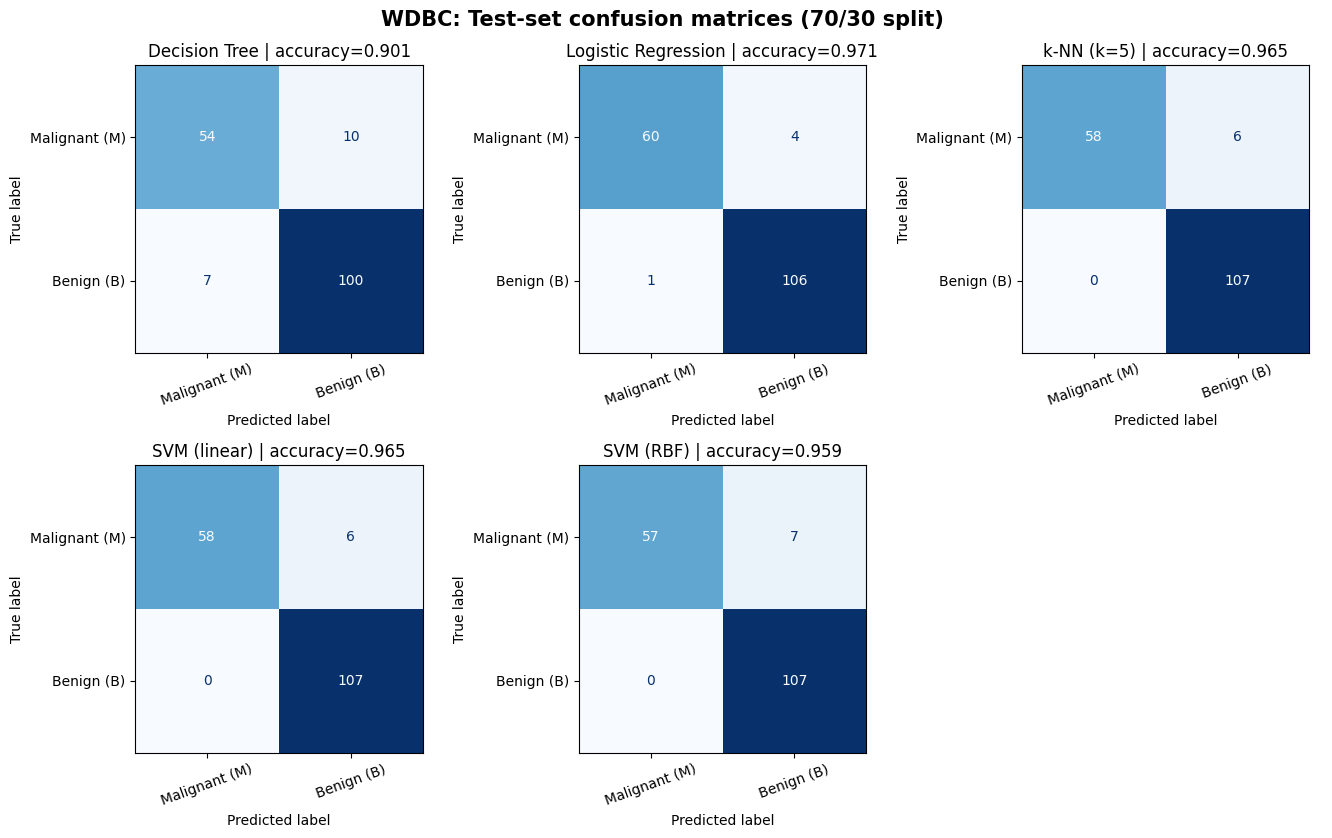

In [9]:
fig,axes=plt.subplots(2,3,figsize=(13.5,8.5))
for ax,(name,pred) in zip(axes.flat,preds.items()):
    cm=confusion_matrix(y_test,pred,labels=class_order)
    disp=ConfusionMatrixDisplay(cm,display_labels=['Malignant (M)','Benign (B)'])
    disp.plot(ax=ax,colorbar=False,cmap='Blues',values_format='d',xticks_rotation=20)
    ax.set_title(f'{name} | accuracy={accuracy_score(y_test,pred):.3f}')
for ax in list(axes.flat)[len(preds):]:ax.axis('off')
fig.suptitle('WDBC: Test-set confusion matrices (70/30 split)',fontsize=15,fontweight='bold')
fig.tight_layout()
fig.savefig('HW3_WDBC_confusion_matrices.png',dpi=170,bbox_inches='tight')
plt.show()

In [10]:
metrics_df=pd.DataFrame(model_metrics).sort_values('Accuracy',ascending=False)
print('Best observed held-out accuracy:',metrics_df.iloc[0]['Model'],'=',round(metrics_df.iloc[0]['Accuracy'],6))
lin=float(metrics_df.loc[metrics_df.Model=='SVM (linear)','Accuracy'].iloc[0])
rbf=float(metrics_df.loc[metrics_df.Model=='SVM (RBF)','Accuracy'].iloc[0])
print('Linear SVM vs RBF SVM (C=1):',round(lin,6),'vs',round(rbf,6))
print('5-NN and linear SVM have identical confusion matrices on this test split:',
      np.array_equal(confusion_matrix(y_test,preds['k-NN (k=5)'],labels=class_order),
                     confusion_matrix(y_test,preds['SVM (linear)'],labels=class_order)))
for name in ['Logistic Regression','SVM (linear)','SVM (RBF)']:
    cm=confusion_matrix(y_test,preds[name],labels=class_order)
    # M is the positive/dangerous category; row M, predicted B counts missed malignant cases.
    print(name,': missed malignant (M classified B) =',int(cm[0,1]),
          'malignant recall =',round(cm[0,0]/cm[0].sum(),4))


Best observed held-out accuracy: Logistic Regression = 0.97076
Linear SVM vs RBF SVM (C=1): 0.964912 vs 0.959064
5-NN and linear SVM have identical confusion matrices on this test split: True
Logistic Regression : missed malignant (M classified B) = 4 malignant recall = 0.9375
SVM (linear) : missed malignant (M classified B) = 6 malignant recall = 0.9062
SVM (RBF) : missed malignant (M classified B) = 7 malignant recall = 0.8906


## Problem 4(ii): Student grade prediction
Encode categorical features using LabelEncoder. Predict G3 with Random Forest (Portuguese) and Gradient Boosting (Mathematics). Evaluate $R^2$, MSE and actual versus predicted plots.


In [11]:
def load_student_data(name):
    data=pd.read_csv(input_path(name),sep=';')
    assert 'G3' in data.columns
    X=data.drop(columns='G3').copy()
    y=data['G3'].astype(float)
    encoded_columns=[]
    for col in X.columns:
        if X[col].dtype=='object' or str(X[col].dtype)=='category':
            enc=LabelEncoder()
            X[col]=enc.fit_transform(X[col].astype(str))
            encoded_columns.append(col)
    assert X.isna().sum().sum()==0
    return data,X,y,encoded_columns

student_results={}
for dataset, expected_n, model in [
    ('student-por.csv',649,RandomForestRegressor(n_estimators=200,random_state=RANDOM_SEED,n_jobs=-1)),
    ('student-mat.csv',395,GradientBoostingRegressor(random_state=RANDOM_SEED))]:
    data,X,y,cols=load_student_data(dataset)
    assert len(data)==expected_n
    xtr,xte,ytr,yte=train_test_split(X,y,test_size=.30,random_state=RANDOM_SEED)
    model.fit(xtr,ytr)
    yp=model.predict(xte)
    r2=r2_score(yte,yp);mse=mean_squared_error(yte,yp)
    student_results[dataset]={'y_test':yte.to_numpy(),'y_pred':yp,'r2':r2,'mse':mse,
                              'train_size':len(xtr),'test_size':len(xte),'model':model,'encoded_columns':cols}
    print(dataset, '| records:',len(data),'| descriptive features:',len(X.columns))
    print('Encoded categorical features:',len(cols),':',', '.join(cols))
    print('Train/test:',len(xtr),len(xte),'| R-squared:',f'{r2:.8f}','| MSE:',f'{mse:.8f}')
    print()

student-por.csv | records: 649 | descriptive features: 32
Encoded categorical features: 17 : school, sex, address, famsize, Pstatus, Mjob, Fjob, reason, guardian, schoolsup, famsup, paid, activities, nursery, higher, internet, romantic
Train/test: 454 195 | R-squared: 0.86132083 | MSE: 1.53353449

student-mat.csv | records: 395 | descriptive features: 32
Encoded categorical features: 17 : school, sex, address, famsize, Pstatus, Mjob, Fjob, reason, guardian, schoolsup, famsup, paid, activities, nursery, higher, internet, romantic
Train/test: 276 119 | R-squared: 0.86553416 | MSE: 2.95583666



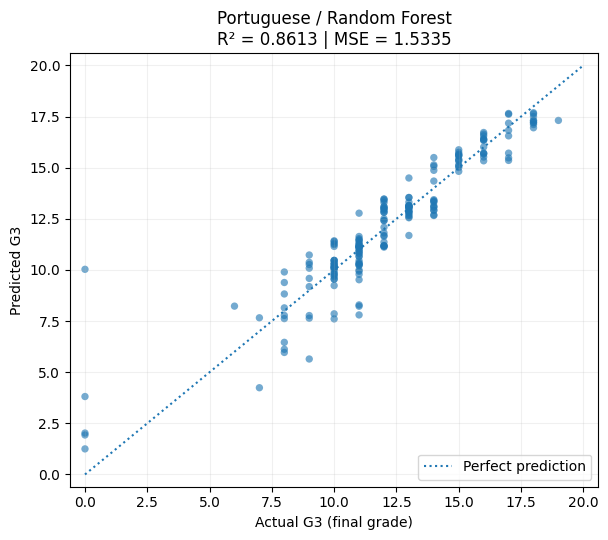

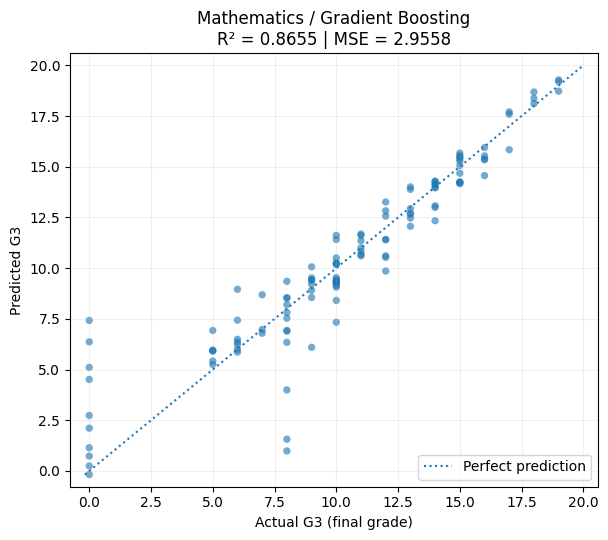

Regression results:


,Dataset,Method,Train rows,Test rows,R²,MSE
0,student-por.csv,Random Forest,454,195,0.861321,1.533534
1,student-mat.csv,Gradient Boosting,276,119,0.865534,2.955837


In [12]:
for dataset, vals in student_results.items():
    actual=vals['y_test']; predicted=vals['y_pred']
    fig,ax=plt.subplots(figsize=(6.2,5.5))
    ax.scatter(actual,predicted,alpha=.62,s=28,edgecolors='none')
    end=max(20,np.max(actual),np.max(predicted));start=min(0,np.min(actual),np.min(predicted))
    ax.plot([start,end],[start,end],linestyle=':',label='Perfect prediction')
    ax.set_xlim(start-.6,end+.6);ax.set_ylim(start-.6,end+.6)
    ax.set_xlabel('Actual G3 (final grade)');ax.set_ylabel('Predicted G3')
    label='Portuguese / Random Forest' if 'por' in dataset else 'Mathematics / Gradient Boosting'
    ax.set_title(label+'\n'+f'R² = {vals["r2"]:.4f} | MSE = {vals["mse"]:.4f}')
    ax.grid(alpha=.18);ax.legend(loc='lower right')
    fig.tight_layout()
    png='HW3_student_por_scatter.png' if 'por' in dataset else 'HW3_student_mat_scatter.png'
    fig.savefig(png,dpi=170,bbox_inches='tight')
    plt.show()
print('Regression results:')
display(pd.DataFrame([{'Dataset':name,'Method':('Random Forest' if 'por' in name else 'Gradient Boosting'),
                       'Train rows':r['train_size'],'Test rows':r['test_size'],
                       'R²':r['r2'],'MSE':r['mse']} for name,r in student_results.items()]).round(6))